# CSE 4095 — Class 3: Regression and Model Error
Use AI to help write unfamiliar code, but verify and explain each modeling decision.

## Setup
Imports, then load the dataset and check its structure and missing values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# keep_default_na=False stops pandas from reading the category "None" as missing.
# Only truly empty cells become NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    str    
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    str    
 6   study_group                   250 non-null    str    
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 19.7 KB


In [4]:
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1 — Regression vs. Classification
Conceptual only, no code.

### Part 1 Questions

**1. Why is this a regression problem?**

**My answer:** Regression problems deal with continuous quantitative values, which is what exam_score, the target, is. 

**2. How is this different from the Class 2 classification problem?**

**My answer:** Classification deals with labels rather than strictly numbers, the classification of last class was high_exam_score, which was a Yes or No value if exam score was >= 80

**3. What information is lost when we convert exam_score into only Yes or No?**

**My answer:** The information is the specifics, how far above or below 80 the student got. A student could've had a 79.999999 and been in the NO group, when functionally they are the same as the >=80 students. 

**4. What kind of output should a regression model produce?**

**My answer:** A regression model should output a number on the same scale as the target, which is exam_score. One prediction per student.

## Part 2 — Understand the Target
Summary statistics, the distribution, and a check for unusual values in `exam_score`.

In [5]:
exam_score_stats = df["exam_score"].agg(["count", "mean", "median", "std", "min", "max"])
exam_score_stats.round(2).to_frame()

,exam_score
count,250.00
mean,77.16
median,76.95
std,10.33
min,51.40
max,100.00


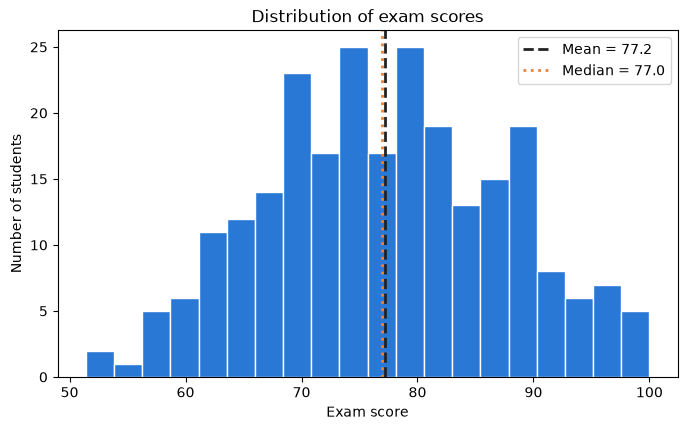

In [6]:
mean_score = df["exam_score"].mean()
median_score = df["exam_score"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["exam_score"], bins=20, color="#2a78d6", edgecolor="white")
ax.axvline(mean_score, color="#222222", linestyle="--", linewidth=2, label=f"Mean = {mean_score:.1f}")
ax.axvline(median_score, color="#e8833a", linestyle=":", linewidth=2, label=f"Median = {median_score:.1f}")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")
ax.set_title("Distribution of exam scores")
ax.legend()
plt.show()

In [7]:
# 1.5 IQR rule: report unusual scores, but keep them in the data
q1 = df["exam_score"].quantile(0.25)
q3 = df["exam_score"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

unusually_low = df[df["exam_score"] < lower_fence]
unusually_high = df[df["exam_score"] > upper_fence]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Fences: below {lower_fence:.2f} or above {upper_fence:.2f}")
print(f"Scores below the lower fence: {len(unusually_low)}")
print(f"Scores above the upper fence: {len(unusually_high)}")

Q1 = 69.50, Q3 = 84.97, IQR = 15.47
Fences: below 46.29 or above 108.19
Scores below the lower fence: 0
Scores above the upper fence: 0


### Part 2 Questions

**1. Describe the distribution of exam scores.**

**My answer:**

**2. Are there unusually low or high values?**

**My answer:**

**3. Why is it useful to understand the target before trying to predict it?**

**My answer:**

## Part 3 — Explore One Relationship
`study_hours_per_week` vs. `exam_score`. The trend line is for visual reference only, it is not one of our models.

Pearson correlation: 0.516 (n = 241 students)


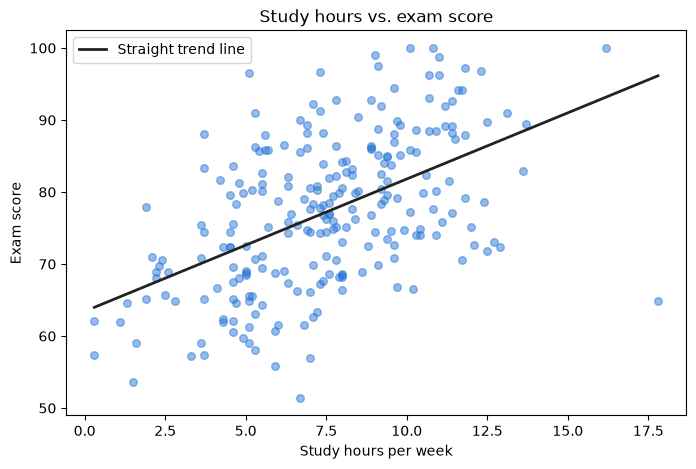

In [8]:
study_and_score = df[["study_hours_per_week", "exam_score"]].dropna()
study_hours = study_and_score["study_hours_per_week"]
scores = study_and_score["exam_score"]

correlation = study_hours.corr(scores)
print(f"Pearson correlation: {correlation:.3f} (n = {len(study_and_score)} students)")

slope, intercept = np.polyfit(study_hours, scores, 1)
line_x = np.linspace(study_hours.min(), study_hours.max(), 100)
line_y = slope * line_x + intercept

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(study_hours, scores, color="#2a78d6", alpha=0.5, s=30)
ax.plot(line_x, line_y, color="#222222", linewidth=2, label="Straight trend line")
ax.set_xlabel("Study hours per week")
ax.set_ylabel("Exam score")
ax.set_title("Study hours vs. exam score")
ax.legend()
plt.show()

> **Reminder:** correlation is not causation. A relationship between study hours and exam scores does not prove that studying more *causes* higher scores. Other factors (motivation, prior experience) could drive both.

### Part 3 Questions

**1. Does there appear to be a relationship?**

**My answer:**

**2. Is the relationship positive or negative?**

**My answer:**

**3. Does it appear approximately linear?**

**My answer:**

**4. Are there students who do not follow the general pattern?**

**My answer:**

## Part 4 — Preprocessing Pipeline
One shared `preprocessor`, and a helper that wraps it with any model so every model gets identical preprocessing.

In [9]:
# Feature columns for the main model.
# Not used as features: student_id, quiz_average, exam_score (the target).
numeric_features = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "commute_minutes",
]
categorical_features = ["prior_programming_experience", "study_group"]

In [10]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])


def make_pipeline_for(model):
    """Return preprocessing + model as one Pipeline.

    clone() gives each pipeline its own unfitted copy of the preprocessor,
    so fitting one model never changes another.
    """
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])


preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### Part 4 Questions

**1. Why should preprocessing be included inside the pipeline?**

**My answer:**

**2. Why is this especially important when using cross-validation?**

**My answer:**

**3. Which of the models in this assignment are sensitive to feature scaling?**

**My answer:**

**4. Do Decision Trees and Random Forests generally require scaling?**

**My answer:**

## 3. Define X and y
Start without `quiz_average`. Explain why `student_id` is excluded.

In [11]:
# TODO: define feature columns, X, and y


## 4. Train/test split and preprocessing
Use an 80/20 split and a pipeline that handles missing values and categorical variables.

In [12]:
# TODO: split data and create preprocessing


## 5. Mean baseline
Predict the training-set mean for every test case and calculate baseline MAE.

In [13]:
# TODO: calculate mean baseline and MAE


## 6. Linear regression
Fit a preprocessing + LinearRegression pipeline using training data only.

In [14]:
# TODO: build, fit, and predict


## 7. Metrics
Calculate MAE, MSE, and R². Compare with the baseline.

In [15]:
# TODO: evaluate predictions


## 8. Prediction table
Create actual, predicted, residual, and absolute-residual columns.

In [16]:
# TODO: build prediction/error table


## 9. Actual vs. predicted plot
Add a perfect-prediction reference line.

In [17]:
# TODO: actual vs predicted plot


## 10. Residual plot
Plot predicted values against residuals and add a horizontal zero line.

In [18]:
# TODO: residual plot


## 11. Largest errors
Find and inspect the five largest absolute residuals.

In [19]:
# TODO: inspect largest errors


## 12. Add quiz_average
Repeat using the same split. Compare metrics and discuss whether the feature is available at prediction time.

In [20]:
# TODO: quiz_average experiment


## 13. Nonlinear model
Try one nonlinear regressor, such as DecisionTreeRegressor, using the same split.

In [21]:
# TODO: nonlinear model experiment


## 14. Your experiment and AI Reflection
State your expectation before running the experiment. Then summarize the evidence and reflect on one AI suggestion you evaluated.

In [22]:
# TODO: your experiment
